# Fine-tuning Laya on Wahy's quote findings (Kaggle, GPU T4 ×2)

Our version of the Laya repo's `notebooks/laya_finetune_typed_decisions_2xT4_kaggle.ipynb`. It trains **three variants
one after another** on the `laya_v1` dataset, evaluates each on the same test set, and compares them with base Laya
and the cached baselines. Walkthrough of every step: `docs/laya-finetune/kaggle-guide.md` in the Wahy repo.

| variant | labels | training data |
|---|---|---|
| `soft_asis` | soft (ε per source and question) | as is (~49 % "not a quote") |
| `soft_balanced` | soft | "not a quote" downsampled to 25 % |
| `hard_asis` | one-hot (ε = 0) | as is |

### Kaggle settings (right-hand panel)
* **Accelerator:** `GPU T4 x2` · **Internet:** `On` (needs a phone-verified account)
* **Input:** add the `laya_v1` dataset you uploaded (any slug: the notebook finds it by its `manifest.json`)
* **Unattended run:** *Save Version → Save & Run All (Commit)*. It runs in the background (up to 12 h) with the browser
  closed; everything lands in the version's **Output** tab (`/kaggle/working`). Expect ~1.5–2 h for the three variants.

## 1. Environment & dual T4 GPU check

In [1]:
!nvidia-smi
import os, subprocess, torch

n_gpu = torch.cuda.device_count()
print(f"CUDA Available: {torch.cuda.is_available()} | Visible GPUs: {n_gpu}")
for i in range(n_gpu):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name} ({p.total_memory / 1e9:.1f} GB)")

assert n_gpu >= 2, (
    f"Expected 2 GPUs, but detected {n_gpu}! Notebook options -> Accelerator -> GPU T4 x2."
)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

Sun Oct 25 15:51:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install dependencies

In [2]:
# CHANGED: pinned to the 0.4 line the Wahy data was validated with (laya.train / laya.calibrate are identical 0.4.12 -> 0.4.15)
!pip install -q -U "laya>=0.4.12,<0.5" "transformers>=4.48.0" safetensors huggingface_hub pandas matplotlib tabulate
import laya, transformers
print("Laya version        :", laya.__version__)
print("Transformers version:", transformers.__version__)
print("PyTorch version     :", torch.__version__)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

## 3. Our dataset and the base checkpoint
**CHANGED vs the original:** the original reads `LocalLLaMA/typed-decisions` from the Hub and trains `convaiinnovations/laya`
— the *English* checkpoint (ModernBERT-large), which cannot read Arabic. We read our JSONL files and train
**`convaiinnovations/laya-multilingual`** (mmBERT-base), the checkpoint the Wahy app runs.

In [3]:
import glob, json, sys
from pathlib import Path
from huggingface_hub import snapshot_download
from laya.agent import _fix_tokenizer_config

DATA = next(Path(p).parent for p in sorted(glob.glob("/kaggle/input/**/manifest.json", recursive=True))
            if json.loads(Path(p).read_text()).get("name") == "laya_v1")

manifest = json.loads((DATA / "manifest.json").read_text())
sys.path.insert(0, str(DATA))
import eval_laya

print("dataset:", DATA, "| created", manifest["created"], "| base model", manifest["base_model"])
for f, n in manifest["files"].items():
    print(f"  {f:28s} {n:5d} rows")
for v, d in manifest["variants"].items():
    print(f"  {v:14s} train rows {d['train_rows']}, 'not a quote' share {d['train_false_share']:.1%} - {d['about']}")

MODEL_ID = manifest["base_model"]          # CHANGED: convaiinnovations/laya-multilingual
model_dir = snapshot_download(MODEL_ID)
_fix_tokenizer_config(model_dir)
print("base checkpoint:", model_dir, json.loads(Path(model_dir, "rl_agent_config.json").read_text())["encoder"])

dataset: /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1 | created 2026-10-25 | base model convaiinnovations/laya-multilingual
  soft_asis/train.jsonl         2863 rows
  soft_asis/val.jsonl            515 rows
  soft_balanced/train.jsonl     1965 rows
  soft_balanced/val.jsonl        515 rows
  hard_asis/train.jsonl         2863 rows
  hard_asis/val.jsonl            515 rows
  test.jsonl                    1523 rows
  test_user.jsonl                198 rows
  soft_asis      train rows 2863, 'not a quote' share 48.5% - soft labels (eps per source and question), training data as is
  soft_balanced  train rows 1965, 'not a quote' share 25.0% - soft labels, 'not a quote' in train downsampled to 25 %
  hard_asis      train rows 2863, 'not a quote' share 48.5% - one-hot labels (eps = 0), training data as is


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

base checkpoint: /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 jhu-clsp/mmBERT-base


## 4. Settings
The defaults are the original notebook's (effective batch 8 × 2 GPUs × 4 = 64, 4 epochs, RLCD). See the guide before
changing them. `VARIANTS` runs in this order; a failing variant is logged and the next one still runs.

In [4]:
VARIANTS = ["soft_asis", "soft_balanced", "hard_asis"]
TRAIN_ARGS = "--epochs 4 --micro-batch 8 --grad-accum 4 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd"
RUN_BASE_EVAL = True        # zero-shot base Laya on the same test set (the "before" line of the comparison)
APP_FALSE_SHARE = 0.10      # the app's real stream is ~10 % "not a quote" (used for the prior-corrected numbers)
PUSH_TO_HUB = True         # True: upload each model to a PRIVATE Hub repo (needs the HF_TOKEN secret)
HUB_PREFIX = "ZenoAbderrahim/laya-wahy"   # repo = f"{HUB_PREFIX}-{variant}"

WORK = Path("/kaggle/working")
(WORK / "results").mkdir(parents=True, exist_ok=True)
(WORK / "logs").mkdir(parents=True, exist_ok=True)

def run(cmd, log):
    """Run a shell command, stream its output here and into a log file; returns the exit code."""
    print("$", cmd, flush=True)
    with open(log, "w") as f:
        p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            f.write(line)
            if "Warning" not in line and "warn(" not in line:
                print(line, end="", flush=True)
        return p.wait()

## 5. Base Laya (zero-shot) on the test set

In [5]:
if RUN_BASE_EVAL:
    rc = run(f'python {DATA}/eval_laya.py predict --model {model_dir} --name "base Laya (zero-shot)" '
             f'--test {DATA}/test.jsonl --out {WORK}/results/base.json --baselines {DATA}/baselines.json '
             f'--batch-size 32', WORK / "logs" / "eval_base.log")
    print("exit code", rc)

$ python /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/eval_laya.py predict --model /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 --name "base Laya (zero-shot)" --test /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/test.jsonl --out /kaggle/working/results/base.json --baselines /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/baselines.json --batch-size 32
  from pandas.core import (
  32/1523 rows, 4s
  672/1523 rows, 45s
  1312/1523 rows, 90s
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 198 | 59.1 % [52–66] | 85.2 % [68–94] | 24.0 % [17–33] | 42.7 % [36–50] | 0.763 | 0.216 | 32.9 % [26–41] |
exit code 0


## 6. Train + evaluate the three variants
Per variant: `torchrun` launches `train_ddp.py` on both GPUs (DDP), then `eval_laya.py` scores the saved model on the test
set. **CHANGED vs the original:** calibration uses our `val.jsonl` (whole held-out lectures) instead of a random 10 % of
training items, and val loss / accuracy is printed after every epoch (the overfitting check).

In [6]:
import time
status = {}
for v in VARIANTS:
    out = WORK / "models" / v
    t0 = time.time()
    try:
        rc = run(f"torchrun --standalone --nproc_per_node=2 {DATA}/train_ddp.py {model_dir} {out} "
                 f"--train {DATA}/{v}/train.jsonl --val {DATA}/{v}/val.jsonl --name laya-wahy-{v} {TRAIN_ARGS}",
                 WORK / "logs" / f"train_{v}.log")
        if rc != 0 or not (out / "model.safetensors").exists():
            status[v] = f"training failed (exit {rc}), see logs/train_{v}.log"
            continue
        share = manifest["variants"][v]["train_false_share"]
        rc = run(f"python {DATA}/eval_laya.py predict --model {out} --name {v} --test {DATA}/test.jsonl "
                 f"--out {WORK}/results/{v}.json --train-false-share {share} --app-false-share {APP_FALSE_SHARE} "
                 f"--batch-size 32", WORK / "logs" / f"eval_{v}.log")
        status[v] = f"ok in {(time.time() - t0) / 60:.0f} min" if rc == 0 else f"evaluation failed (exit {rc})"
    except Exception as e:
        status[v] = f"error: {e}"
    print(f"\n##### {v}: {status[v]}\n", flush=True)
json.dump(status, open(WORK / "results" / "status.json", "w"), indent=1)
status

$ torchrun --standalone --nproc_per_node=2 /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/train_ddp.py /root/.cache/huggingface/hub/models--convaiinnovations--laya-multilingual/snapshots/1720e3e3357cfe1e281542e223f8273b0890ca34 /kaggle/working/models/soft_asis --train /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/soft_asis/train.jsonl --val /kaggle/input/datasets/abderrahimzineddine/laya-v1/datasets/laya_v1/soft_asis/val.jsonl --name laya-wahy-soft_asis --epochs 4 --micro-batch 8 --grad-accum 4 --lr-encoder 2.5e-5 --lr-head 1e-4 --loss rlcd
W1025 15:55:32.144000 116 torch/distributed/run.py:851] 
W1025 15:55:32.144000 116 torch/distributed/run.py:851] *****************************************
W1025 15:55:32.144000 116 torch/distributed/run.py:851] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application a

{'soft_asis': 'ok in 35 min',
 'soft_balanced': 'ok in 30 min',
 'hard_asis': 'ok in 35 min'}

## 7. Comparison
One table per test group. Rates are shown as `value [95 % interval]`: on your 198 cards (27 "not a quote") one mistake moves
the "not a quote" recall by ~4 points, so read the intervals before calling a difference real. Cached baselines (JEV / Gemini /
base Laya from the review notebook) only cover some test cards: the `cards` column says how many.

In [7]:
from IPython.display import Markdown, display
files = sorted(glob.glob(str(WORK / "results" / "*.json")))
results = [json.load(open(f)) for f in files if not f.endswith("status.json")]
order = {"base Laya (zero-shot)": 0, **{v: i + 1 for i, v in enumerate(VARIANTS)}}
results.sort(key=lambda r: order.get(r["name"], 99))
report = []
for g in ["you", "you + Sonnet", "Sonnet · review lessons", "Sonnet · other lectures", "written text"]:
    t = f"### {g}\n" + eval_laya.compare(results, g)
    report.append(t)
    display(Markdown(t))
(WORK / "results" / "comparison.md").write_text("\n\n".join(report))

### you
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 198 | 59.1 % [52–66] | 85.2 % [68–94] | 24.0 % [17–33] | 42.7 % [36–50] | 0.763 | 0.216 | 32.9 % [26–41] |
| soft_asis | 198 | 91.4 % [87–95] | 77.8 % [59–89] | 65.6 % [48–80] | 6.4 % [4–11] | 0.944 | 0.084 | 44.8 % [37–53] |
| soft_balanced | 198 | 91.4 % [87–95] | 44.4 % [28–63] | 85.7 % [60–96] | 1.2 % [0–4] | 0.882 | 0.102 | 46.2 % [38–54] |
| hard_asis | 198 | 90.4 % [86–94] | 85.2 % [68–94] | 60.5 % [45–74] | 8.8 % [5–14] | 0.945 | 0.040 | 44.8 % [37–53] |
| 7 shallow fields (LR) | 198 | 83.8 % [78–88] | 66.7 % [48–81] | 43.9 % [30–59] | 13.5 % [9–19] | 0.857 | 0.040 | — |
| Gemini (cached) | 147 | 89.8 % [84–94] | 41.7 % [24–61] | 100.0 % [72–100] | 0.0 % [0–3] | 0.708 | 0.102 | 50.0 % [40–60] |
| JEV (cached) | 147 | 86.4 % [80–91] | 20.8 % [9–40] | 100.0 % [57–100] | 0.0 % [0–3] | 0.604 | 0.136 | 52.9 % [43–62] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 198 | 79.3 % [73–84] | 29.6 % [16–48] | 26.7 % [14–44] | 12.9 % [9–19] | 0.723 | 0.109 | — |

### you + Sonnet
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 1243 | 62.4 % [60–65] | 78.0 % [74–81] | 58.2 % [55–62] | 49.1 % [45–53] | 0.722 | 0.150 | 33.1 % [30–37] |
| soft_asis | 1243 | 90.9 % [89–92] | 92.4 % [90–94] | 88.6 % [86–91] | 10.4 % [8–13] | 0.960 | 0.082 | 70.8 % [67–74] |
| soft_balanced | 1243 | 86.3 % [84–88] | 75.9 % [72–79] | 93.6 % [91–96] | 4.5 % [3–6] | 0.947 | 0.076 | 69.2 % [66–73] |
| hard_asis | 1243 | 90.7 % [89–92] | 95.7 % [94–97] | 85.9 % [83–88] | 13.8 % [11–17] | 0.962 | 0.041 | 69.4 % [66–73] |
| 7 shallow fields (LR) | 1243 | 85.5 % [83–87] | 89.3 % [87–92] | 81.5 % [78–84] | 17.8 % [15–21] | 0.932 | 0.035 | — |
| Gemini (cached) | 180 | 90.0 % [85–94] | 38.5 % [22–57] | 90.9 % [62–98] | 0.7 % [0–4] | 0.689 | 0.100 | 51.9 % [43–60] |
| JEV (cached) | 180 | 87.2 % [82–91] | 19.2 % [9–38] | 83.3 % [44–97] | 0.7 % [0–4] | 0.593 | 0.128 | 54.9 % [46–63] |
| Laya (base) (cached) | 111 | 54.0 % [45–63] | 88.9 % [56–98] | 14.0 % [7–25] | 48.0 % [39–58] | 0.704 | 0.460 | 30.4 % [22–40] |
| span length only (LR) | 1243 | 81.7 % [79–84] | 78.7 % [75–82] | 81.5 % [78–84] | 15.7 % [13–19] | 0.890 | 0.042 | — |

### Sonnet · review lessons
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 449 | 66.8 % [62–71] | 74.9 % [70–80] | 74.9 % [70–80] | 44.4 % [37–52] | 0.745 | 0.098 | 23.5 % [18–31] |
| soft_asis | 449 | 90.6 % [88–93] | 94.8 % [92–97] | 91.0 % [87–94] | 16.7 % [12–23] | 0.959 | 0.110 | 70.4 % [63–77] |
| soft_balanced | 449 | 86.4 % [83–89] | 82.9 % [78–87] | 95.2 % [92–97] | 7.4 % [4–12] | 0.949 | 0.078 | 66.0 % [58–73] |
| hard_asis | 449 | 90.2 % [87–93] | 97.6 % [95–99] | 88.3 % [84–91] | 22.8 % [17–30] | 0.952 | 0.050 | 67.9 % [60–75] |
| 7 shallow fields (LR) | 449 | 84.9 % [81–88] | 89.2 % [85–92] | 87.4 % [83–91] | 22.8 % [17–30] | 0.911 | 0.034 | — |
| Gemini (cached) | 33 | 90.9 % [76–97] | 0.0 % [0–66] | 0.0 % [0–79] | 3.2 % [1–16] | 0.484 | 0.091 | 58.1 % [41–74] |
| JEV (cached) | 33 | 90.9 % [76–97] | 0.0 % [0–66] | 0.0 % [0–79] | 3.2 % [1–16] | 0.484 | 0.091 | 61.3 % [44–76] |
| span length only (LR) | 449 | 82.4 % [79–86] | 81.2 % [76–85] | 90.3 % [86–93] | 15.4 % [11–22] | 0.895 | 0.093 | — |

### Sonnet · other lectures
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 596 | 60.2 % [56–64] | 80.5 % [75–85] | 54.4 % [50–59] | 54.7 % [49–60] | 0.707 | 0.186 | 38.0 % [33–43] |
| soft_asis | 596 | 90.9 % [88–93] | 91.4 % [87–94] | 88.7 % [84–92] | 9.4 % [7–13] | 0.957 | 0.074 | 82.4 % [78–86] |
| soft_balanced | 596 | 84.6 % [81–87] | 71.5 % [66–77] | 92.3 % [88–95] | 4.9 % [3–8] | 0.942 | 0.079 | 80.8 % [76–85] |
| hard_asis | 596 | 91.1 % [89–93] | 94.8 % [91–97] | 86.6 % [82–90] | 11.8 % [9–16] | 0.963 | 0.042 | 80.8 % [76–85] |
| 7 shallow fields (LR) | 596 | 86.6 % [84–89] | 91.8 % [88–94] | 80.9 % [76–85] | 17.6 % [14–22] | 0.941 | 0.057 | — |
| span length only (LR) | 596 | 81.9 % [79–85] | 80.9 % [76–85] | 79.1 % [74–84] | 17.3 % [14–22] | 0.897 | 0.051 | — |

### written text
| model | cards | verdict accuracy | not-a-quote recall | not-a-quote precision | real wrongly rejected | AUC | ECE | boundary accuracy |
|---|---|---|---|---|---|---|---|---|
| base Laya (zero-shot) | 280 | 48.2 % [42–54] | 50.0 % [19–81] | 2.3 % [1–7] | 46.0 % [40–52] | 0.495 | 0.285 | 36.2 % [31–42] |
| soft_asis | 280 | 90.4 % [86–93] | 83.3 % [44–97] | 16.1 % [7–33] | 9.5 % [7–14] | 0.843 | 0.073 | 62.4 % [56–68] |
| soft_balanced | 280 | 94.6 % [91–97] | 50.0 % [19–81] | 20.0 % [7–45] | 4.4 % [3–8] | 0.889 | 0.133 | 63.1 % [57–69] |
| hard_asis | 280 | 87.1 % [83–91] | 83.3 % [44–97] | 12.5 % [5–26] | 12.8 % [9–17] | 0.847 | 0.073 | 62.7 % [57–68] |
| 7 shallow fields (LR) | 280 | 92.9 % [89–95] | 83.3 % [44–97] | 20.8 % [9–40] | 6.9 % [4–11] | 0.904 | 0.051 | — |
| span length only (LR) | 280 | 82.9 % [78–87] | 83.3 % [44–97] | 9.6 % [4–21] | 17.2 % [13–22] | 0.919 | 0.169 | — |

5640

## 8. Training curves and calibration
Left: training loss (logged every 50 micro-batches on GPU 0). Right: val loss per epoch — if it rises while training loss
keeps falling, the model is memorising (fewer epochs). The fitted temperature > 1 means the model was over-confident on val
and is softened; < 1 sharpened.

soft_asis      32 min | temperature (choice) 1.2839607000350952 | val accuracy 0.8614 | ECE at T=1 0.0455 -> at fitted T 0.067 | issues []
soft_balanced  27 min | temperature (choice) 1.3629285097122192 | val accuracy 0.8421 | ECE at T=1 0.046 -> at fitted T 0.0674 | issues []
hard_asis      32 min | temperature (choice) 5.0 | val accuracy 0.8588 | ECE at T=1 0.1345 -> at fitted T 0.07 | issues ['the fitted temperature 5 is on the [0.5, 5] clamp']


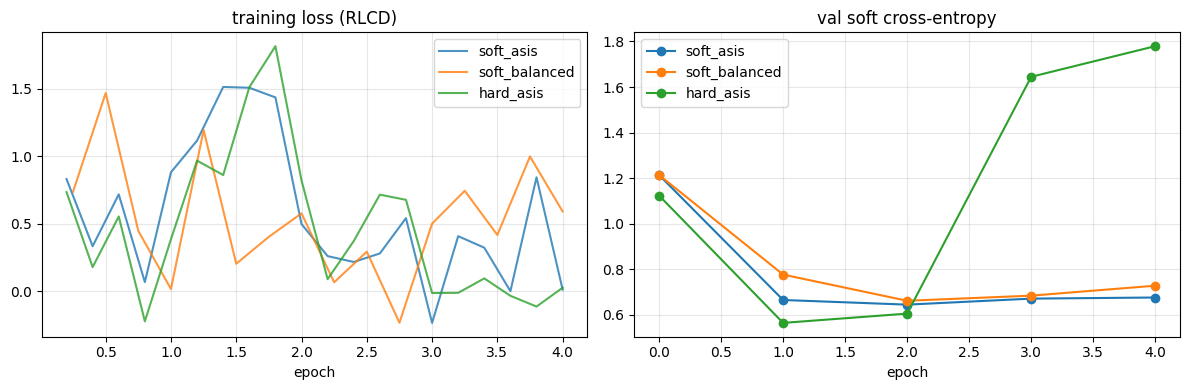

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for v in VARIANTS:
    p = WORK / "models" / v / "train_log.json"
    if not p.exists():
        continue
    h = json.load(open(p))
    spe = max(1, max(s["step"] for s in h["steps"])) if h["steps"] else 1
    ax[0].plot([(s["epoch"] - 1) + s["step"] / spe for s in h["steps"]], [s["loss"] for s in h["steps"]], label=v, alpha=.8)
    ep = [0] + [e["epoch"] for e in h["epochs"]]
    ax[1].plot(ep, [h["val_before"]["all"]["loss"]] + [e["val"]["all"]["loss"] for e in h["epochs"]], marker="o", label=v)
    cal = h.get("calibration", {})
    print(f"{v:14s} {h['seconds'] / 60:.0f} min | temperature (choice) {cal.get('temperature', ['?'])[0]} | "
          f"val accuracy {cal.get('val_at_fitted', {}).get('accuracy')} | ECE at T=1 {cal.get('val_at_t1', {}).get('ece')} "
          f"-> at fitted T {cal.get('val_at_fitted', {}).get('ece')} | issues {cal.get('report', {}).get('choice', {}).get('issues')}")
ax[0].set(title="training loss (RLCD)", xlabel="epoch"); ax[1].set(title="val soft cross-entropy", xlabel="epoch")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(WORK / "results" / "curves.png", dpi=120); plt.show()

## 9. Details on your labels: confusion matrix, threshold, span length, calibration
For each model: what it does with your 198 cards. *Prior-corrected* = the decision after shifting the probabilities from the
training class balance to the app's (~10 % "not a quote"). *Threshold sweep* = reject only when P(not a quote) ≥ t: a higher t
rejects fewer real quotes and catches fewer false findings.

In [9]:
import pandas as pd
for r in results:
    g = r["groups"].get("you", {})
    v, b = g.get("verdict"), g.get("boundary")
    if not v:
        continue
    display(Markdown(f"#### {r['name']}"))
    display(pd.DataFrame(v["confusion (gold -> predicted)"]).T.rename_axis("gold \\ predicted"))
    pc = [k for k in v if k.startswith("prior-corrected")]
    if pc:
        print(pc[0], {k: eval_laya._fmt(x) if isinstance(x, list) else x for k, x in v[pc[0]].items()})
    display(pd.DataFrame([{k: eval_laya._fmt(x) if isinstance(x, list) else x for k, x in t.items()} for t in v["threshold sweep (reject if P(not a quote) >= t)"]]))
    display(pd.DataFrame([{k: eval_laya._fmt(x) if isinstance(x, list) else x for k, x in t.items()} for t in v["by span length"]]))
    display(pd.DataFrame(v["reliability"]))
    if b:
        print("boundary accuracy", eval_laya._fmt(b["accuracy"]))
        display(pd.DataFrame(b["confusion (gold -> predicted)"]).T)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


#### base Laya (zero-shot)

,CORRECT,FALSE,NOT_SURE
gold \ predicted,,,
CORRECT,94,73,4
FALSE,4,23,0


,t,not-a-quote precision,not-a-quote recall,real quotes wrongly rejected,wrongly rejected (count)
0,0.50,25.9 % [18–36],81.5 % [63–92],36.8 % [30–44],63/171
1,0.60,27.0 % [18–38],74.1 % [55–87],31.6 % [25–39],54/171
2,0.70,27.7 % [18–40],66.7 % [48–81],27.5 % [21–35],47/171
3,0.80,33.3 % [21–48],55.6 % [37–72],17.5 % [13–24],30/171
4,0.90,32.1 % [18–51],33.3 % [19–52],11.1 % [7–17],19/171
5,0.95,40.0 % [22–61],29.6 % [16–48],7.0 % [4–12],12/171


,span,cards,real,not a quote,accuracy,not-a-quote precision,not-a-quote recall,real quotes wrongly rejected,wrongly rejected (count)
0,1-3 words,17,11,6,64.7 % [41–83],55.6 % [27–81],83.3 % [44–97],36.4 % [15–65],4/11
1,4-8 words,75,60,15,49.3 % [38–60],26.1 % [16–40],80.0 % [55–93],56.7 % [44–68],34/60
2,9+ words,106,100,6,65.1 % [56–74],14.6 % [7–28],100.0 % [61–100],35.0 % [26–45],35/100


...

#### span length only (LR)

,CORRECT,FALSE,NOT_SURE
gold \ predicted,,,
CORRECT,149,22,0
FALSE,19,8,0


,t,not-a-quote precision,not-a-quote recall,real quotes wrongly rejected,wrongly rejected (count)
0,0.50,26.7 % [14–44],29.6 % [16–48],12.9 % [9–19],22/171
1,0.60,26.7 % [14–44],29.6 % [16–48],12.9 % [9–19],22/171
2,0.70,35.3 % [17–59],22.2 % [11–41],6.4 % [4–11],11/171
3,0.80,0.0 % [0–66],0.0 % [0–12],1.2 % [0–4],2/171
4,0.90,0.0 % [0–79],0.0 % [0–12],0.6 % [0–3],1/171
5,0.95,0.0 % [0–79],0.0 % [0–12],0.6 % [0–3],1/171


,span,cards,real,not a quote,accuracy,not-a-quote precision,not-a-quote recall,real quotes wrongly rejected,wrongly rejected (count)
0,1-3 words,17,11,6,35.3 % [17–59],35.3 % [17–59],100.0 % [61–100],100.0 % [74–100],11/11
1,4-8 words,75,60,15,68.0 % [57–77],15.4 % [4–42],13.3 % [4–38],18.3 % [11–30],11/60
2,9+ words,106,100,6,94.3 % [88–97],—,0.0 % [0–39],0.0 % [0–4],0/100


,bin,cards,mean predicted,observed
0,0.0-0.2,106,0.062,0.057
1,0.2-0.4,41,0.317,0.220
2,0.4-0.6,21,0.493,0.190
3,0.6-0.8,28,0.693,0.286
4,0.8-1.0,2,0.916,0.000


## 10. (Optional) Push to the Hugging Face Hub — private
Add `HF_TOKEN` (a *write* token) under *Add-ons → Secrets*, set `PUSH_TO_HUB = True` and `HUB_PREFIX` in section 4.
Without it, download the models from the version's **Output** tab (`models/<variant>/`).

In [10]:
if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    from kaggle_secrets import UserSecretsClient
    api = HfApi(token=UserSecretsClient().get_secret("HF_TOKEN"))
    for v in VARIANTS:
        out = WORK / "models" / v
        if not (out / "model.safetensors").exists():
            continue
        repo = f"{HUB_PREFIX}-{v}"
        api.create_repo(repo, repo_type="model", private=True, exist_ok=True)
        api.upload_folder(folder_path=str(out), repo_id=repo, repo_type="model",
                          commit_message=f"laya-multilingual fine-tuned on Wahy laya_v1 ({v})")
        print("pushed", repo)

pushed ZenoAbderrahim/laya-wahy-soft_asis
pushed ZenoAbderrahim/laya-wahy-soft_balanced
pushed ZenoAbderrahim/laya-wahy-hard_asis
